# Module 05: From snowpack to streamflow forecast

*The code behind GEOS 212: Water in the West, Boise State University*

Every spring, water managers across the West ask the same question: **how much water will the rivers carry this summer?** Farmers decide what to plant, reservoir operators decide how much to release, and cities plan for shortages, all based on a *water supply forecast*.

The simplest forecasts rest on one idea from lecture: the snowpack on April 1 is a reservoir, and most of it will become April-July streamflow. If we know how big the snow reservoir is, we can predict how much water is coming.

In this notebook we'll build a forecast like that ourselves, using:

* **Banner Summit SNOTEL** (site 312, 7,040 ft), in the headwaters of the South Fork Payette River, and
* **USGS 13235000, South Fork Payette River at Lowman**, an unregulated river just downstream (no dams above it).

We'll also look at how snow *settles and densifies* through the winter, which is why we measure SWE and not just snow depth.

**Where are we in the water year?** In the *snowpack*, looking ahead to the *river*.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

In [2]:
def water_year(dates):
    """Water year: Oct 1 2025 - Sep 30 2026 is water year 2026."""
    return dates.year + (dates.month >= 10)

def wy_axis_date(dates):
    """Map every date onto one shared 'generic' water year (Oct 2000 - Sep 2001),
    so different years can be drawn on the same x-axis."""
    return pd.to_datetime([pd.Timestamp(2000 if d.month >= 10 else 2001, d.month, min(d.day, 28) if d.month == 2 else d.day)
                           for d in dates])

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

## 2. Getting the data

Two download functions: one for SNOTEL (from the NRCS Report Generator) and one for daily streamflow (from USGS). Notice how each web address spells out the site, the dates and the variables we want. `WTEQ` = snow water equivalent, `PREC` = accumulated precipitation, `SNWD` = snow depth.

In [3]:
def get_snotel(site, state, start, end, elements="WTEQ::value,PREC::value"):
    """Daily SNOTEL data from the NRCS Report Generator, as a table indexed by date."""
    url = ("https://wcc.sc.egov.usda.gov/reportGenerator/view_csv/customSingleStationReport/daily/"
           f"{site}:{state}:SNTL%7Cid=%22%22%7Cname/{start},{end}/{elements}")
    tag = elements.replace("::", "-").replace(",", "_")
    text = fetch_text(url, f"snotel_{site}_{start}_{end}_{tag}.csv")
    return pd.read_csv(io.StringIO(text), comment="#", parse_dates=["Date"], index_col="Date")

In [4]:
def get_usgs_daily_flow(site, start, end):
    """Daily mean discharge (cubic feet per second, cfs) from USGS NWIS.
    Returns a pandas Series indexed by date."""
    url = ("https://waterservices.usgs.gov/nwis/dv/?format=rdb"
           f"&sites={site}&parameterCd=00060&statCd=00003&startDT={start}&endDT={end}")
    text = fetch_text(url, f"usgs_{site}_{start}_{end}.rdb")
    # USGS "rdb" files are tab-separated, with '#' comment lines and a
    # second header row that describes column widths (we skip it).
    df = pd.read_csv(io.StringIO(text), sep="\t", comment="#", dtype=str).iloc[1:]
    flow_col = [c for c in df.columns if c.endswith("_00060_00003")][0]
    q = pd.to_numeric(df[flow_col], errors="coerce")   # turns codes like 'Ice' into NaN
    q.index = pd.to_datetime(df["datetime"])
    return q.dropna().rename("Q_cfs")

We'll download 45 years of data: water years 1981 through 2025. We'll also grab Banner Summit's snowpack on **April 1, 2026**, the day we'll make our forecast.

Notice that we only download streamflow through September 2025. That's on purpose: on April 1, 2026, a forecaster couldn't know what the river would do that summer, and neither do we (yet).

In [5]:
banner = get_snotel(312, "ID", "1980-10-01", "2026-04-01")
banner.columns = ["swe", "precip"]

lowman = get_usgs_daily_flow("13235000", "1980-10-01", "2025-09-30")
print(f"SNOTEL days: {len(banner):,}    streamflow days: {len(lowman):,}")

Downloaded live data -> snotel_312_1980-10-01_2026-04-01_WTEQ-value_PREC-value.csv


Downloaded live data -> usgs_13235000_1980-10-01_2025-09-30.rdb
SNOTEL days: 16,619    streamflow days: 16,436


## 3. Snow becomes river

First, let's see the connection. We'll plot Banner Summit's median SWE above Lowman's median daily flow for 1991-2020, with April-July shaded.

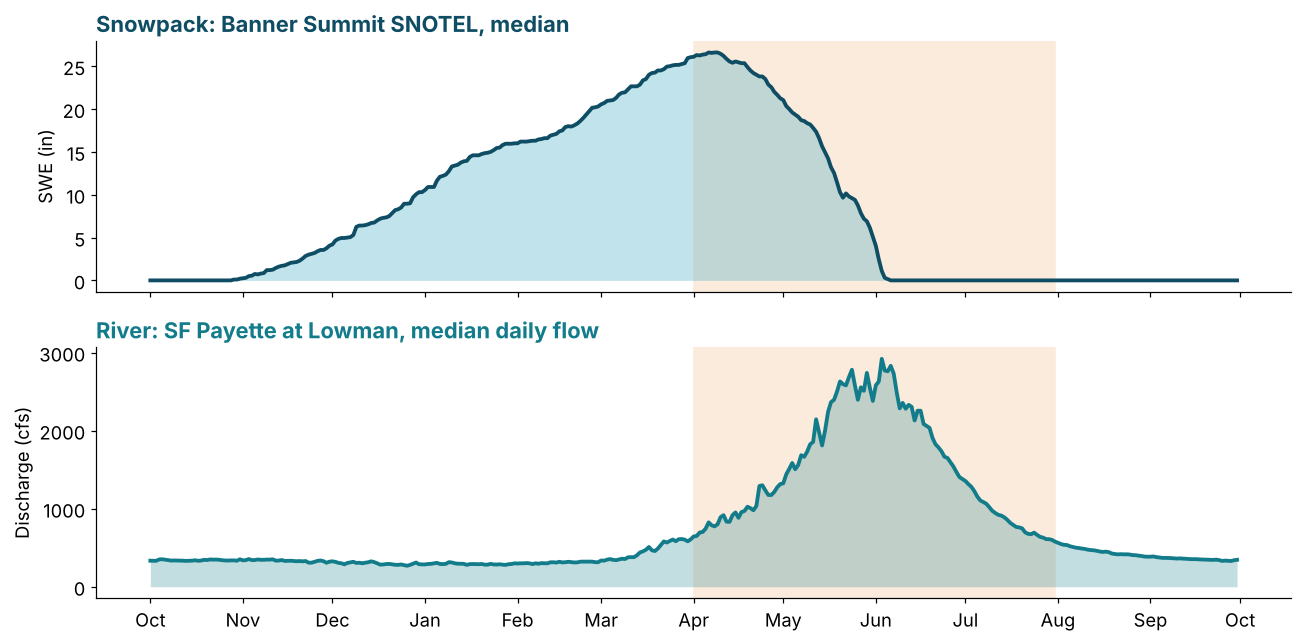

In [6]:
CFS_DAY_TO_AF = 86400 / 43560   # 1 cfs for 1 day = 1.9835 acre-feet

def wy_median(series, first=1991, last=2020):
    s = series[(water_year(series.index) >= first) & (water_year(series.index) <= last)]
    s = s[~((s.index.month == 2) & (s.index.day == 29))]      # drop leap days
    return s.groupby(wy_axis_date(s.index)).median()

swe_med = wy_median(banner.swe)
q_med = wy_median(lowman)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax in (a1, a2):
    ax.axvspan(pd.Timestamp("2001-04-01"), pd.Timestamp("2001-07-31"), color="#FBEBDC", zorder=0)
a1.fill_between(swe_med.index, swe_med, color=GLACIER, alpha=0.35, lw=0); a1.plot(swe_med.index, swe_med, color=DEEP, lw=2.5)
a1.set_ylabel("SWE (in)"); a1.set_title("Snowpack: Banner Summit SNOTEL, median", loc="left", color=DEEP, fontweight="bold")
a2.fill_between(q_med.index, q_med, color=RIVER, alpha=0.25, lw=0); a2.plot(q_med.index, q_med, color=RIVER, lw=2.5)
a2.set_ylabel("Discharge (cfs)"); a2.set_title("River: SF Payette at Lowman, median daily flow", loc="left", color=RIVER, fontweight="bold")
month_axis(a2)
plt.tight_layout()

Now let's put numbers on it. For each water year we'll compute:

* **April 1 SWE** at Banner Summit (inches), and
* the **April-July streamflow volume** at Lowman, in thousand acre-feet (KAF): the sum of daily flows from April 1 to July 31, times 1.9835.

We'll only keep years with a complete record (all 122 days from April through July).

In [7]:
rows = []
for wy in range(1981, 2026):
    apr_jul = lowman[f"{wy}-04-01":f"{wy}-07-31"]
    whole_year = lowman[f"{wy-1}-10-01":f"{wy}-09-30"]
    if len(apr_jul) < 122 or len(whole_year) < 365:
        continue
    rows.append({"wy": wy,
                 "apr1_swe": banner.loc[f"{wy}-04-01", "swe"],
                 "aj_volume_kaf": apr_jul.sum() * CFS_DAY_TO_AF / 1000,
                 "aj_share": apr_jul.sum() / whole_year.sum()})
years = pd.DataFrame(rows).set_index("wy")
print(f"{len(years)} complete years. On average, April-July carries {100 * years.aj_share.mean():.0f}% of the year's flow.")
years.head()

45 complete years. On average, April-July carries 67% of the year's flow.


,apr1_swe,aj_volume_kaf,aj_share
wy,,,
1981,20.3,372.739835,0.662225
1982,34.7,677.416860,0.745585
1983,33.9,602.314711,0.713560
1984,26.4,525.100165,0.679552
1985,26.6,346.478678,0.657170


## 4. Building the forecast: a straight line

Plot April 1 SWE (x) against April-July volume (y). If snow really drives summer streamflow, the points should line up.

We fit a straight line, $V = m \times \text{SWE} + b$, using `np.polyfit` (the same function you used in the Module 07 lab). It finds the slope $m$ and intercept $b$ that make the squared vertical distances from the points to the line as small as possible: a **least-squares** fit.

$R^2$ tells us what fraction of the year-to-year variation in volume the line explains (1 = perfect, 0 = no relationship).

V = 18.8 x SWE -63.7
R^2 = 0.81
Typical miss (standard error): 64 KAF


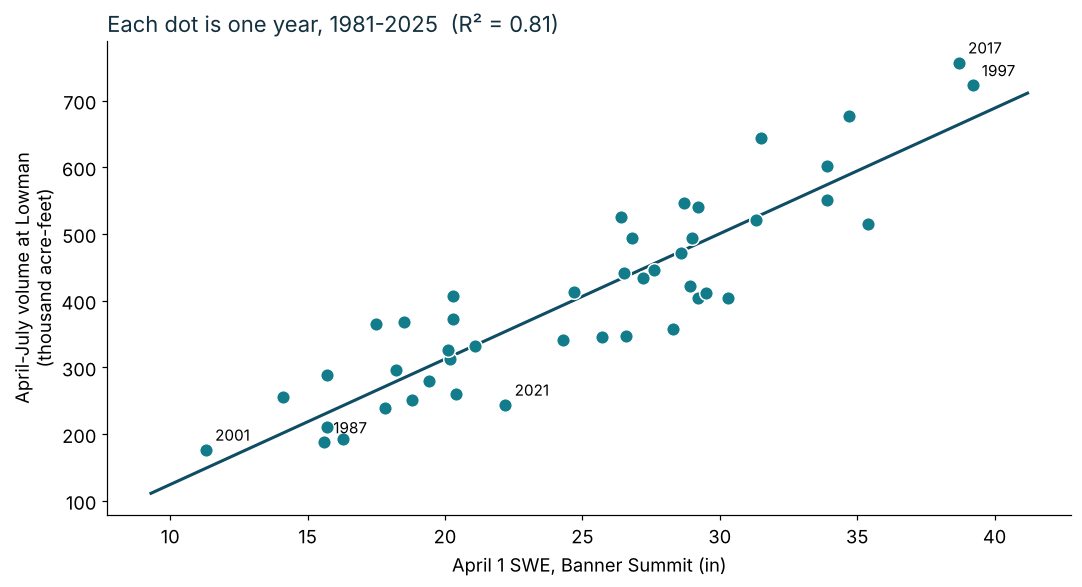

In [8]:
x, y = years.apr1_swe.values, years.aj_volume_kaf.values
m, b = np.polyfit(x, y, 1)
predicted = m * x + b
r2 = np.corrcoef(x, y)[0, 1] ** 2
n = len(x)
s = np.sqrt(np.sum((y - predicted) ** 2) / (n - 2))   # typical size of a miss (standard error)

print(f"V = {m:.1f} x SWE {b:+.1f}")
print(f"R^2 = {r2:.2f}")
print(f"Typical miss (standard error): {s:.0f} KAF")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(x, y, s=80, color=RIVER, edgecolor="white", zorder=3)
xs = np.array([x.min() - 2, x.max() + 2])
ax.plot(xs, m * xs + b, color=DEEP, lw=2)
for wy in [1987, 1997, 2001, 2017, 2021]:
    ax.annotate(str(wy), (years.loc[wy, "apr1_swe"], years.loc[wy, "aj_volume_kaf"]),
                xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.set_xlabel("April 1 SWE, Banner Summit (in)")
ax.set_ylabel("April-July volume at Lowman\n(thousand acre-feet)")
ax.set_title(f"Each dot is one year, {years.index.min()}-{years.index.max()}  (R² = {r2:.2f})", loc="left", color=INK)
plt.tight_layout()

**What does the slope mean physically?** Each extra inch of April 1 SWE at one point on Banner Summit goes with about this many thousand acre-feet more summer flow at Lowman. One station can't measure the whole basin, so the line is really calibrating a *point* measurement to a *basin-wide* response.

## 5. Making the April 1, 2026 forecast

Now we play forecaster. What was the SWE at Banner Summit on April 1, 2026, and what does our line predict?

A single number isn't an honest forecast; we also need the **uncertainty**. The 95% *prediction interval* is the range we expect the actual volume to fall in 19 years out of 20. It depends on how scattered the points are around the line ($s$), how many years we have ($n$), and how far this year's SWE is from the average.

April 1, 2026 SWE at Banner Summit: 16.3 in (62% of the 1991-2020 median)
Forecast April-July 2026 volume: 243 KAF  (95% range 110 to 375 KAF)
For comparison, the 1991-2020 median volume is 410 KAF


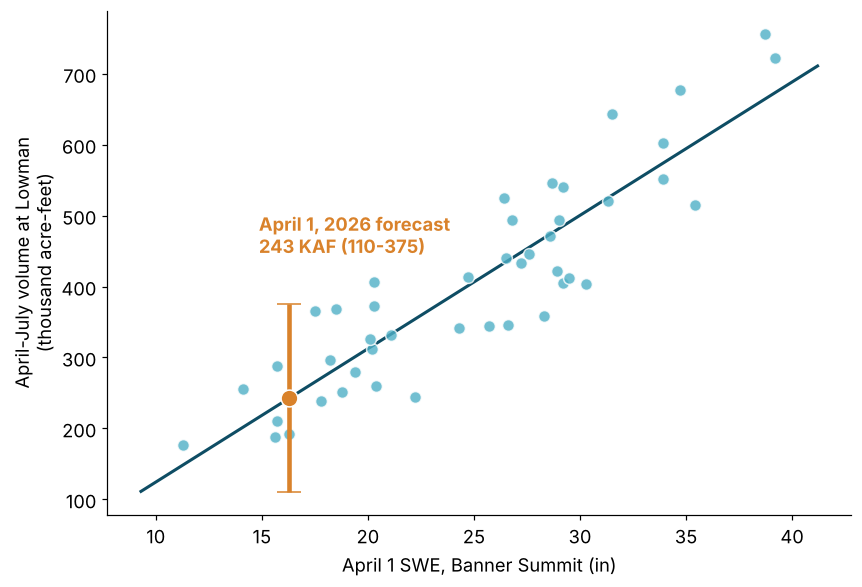

In [9]:
from scipy import stats

swe_2026 = banner.loc["2026-04-01", "swe"]
forecast = m * swe_2026 + b

t = stats.t.ppf(0.975, n - 2)
se_pred = s * np.sqrt(1 + 1/n + (swe_2026 - x.mean())**2 / np.sum((x - x.mean())**2))
low, high = forecast - t * se_pred, forecast + t * se_pred

median_swe = years.loc[1991:2020, "apr1_swe"].median()
median_vol = years.loc[1991:2020, "aj_volume_kaf"].median()
print(f"April 1, 2026 SWE at Banner Summit: {swe_2026:.1f} in ({100 * swe_2026 / median_swe:.0f}% of the 1991-2020 median)")
print(f"Forecast April-July 2026 volume: {forecast:.0f} KAF  (95% range {low:.0f} to {high:.0f} KAF)")
print(f"For comparison, the 1991-2020 median volume is {median_vol:.0f} KAF")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(x, y, s=60, color=GLACIER, edgecolor="white", alpha=0.8, zorder=3)
ax.plot(xs, m * xs + b, color=DEEP, lw=2)
ax.errorbar([swe_2026], [forecast], yerr=[[forecast - low], [high - forecast]], fmt="o", ms=11,
            color=OCHRE, mec="white", elinewidth=3, capsize=8, zorder=5)
ax.annotate(f"April 1, 2026 forecast\n{forecast:.0f} KAF ({low:.0f}-{high:.0f})", (swe_2026, forecast),
            xytext=(-20, 95), textcoords="offset points", color=OCHRE, fontweight="bold")
ax.set_xlabel("April 1 SWE, Banner Summit (in)")
ax.set_ylabel("April-July volume at Lowman\n(thousand acre-feet)")
plt.tight_layout()

So how did the forecast do? We're not going to tell you. Finding out is your first "Your turn" exercise below. (Hint: think back to the Module 04 notebook. What kind of winter was WY2026, and what might a warm winter do to the snow-to-streamflow relationship?)

## 6. Why SWE and not snow depth? Snow densifies

A snowpack isn't a fixed block. Fresh snow is mostly air (density around 50-100 kg/m³); over the winter it compacts under its own weight and as grains change shape, reaching 300-500 kg/m³ by spring. So snow *depth* can drop while the *water* in the snowpack stays the same.

Bulk density comes straight from the two measurements:

$$\rho_{snow} = \rho_{water} \times \frac{\text{SWE}}{h_s} = 1000\ \tfrac{\text{kg}}{\text{m}^3} \times \frac{\text{SWE}}{\text{depth}}$$

Let's download snow depth at Banner Summit for WY2026 and watch the snowpack settle.

Downloaded live data -> snotel_312_2025-10-01_2026-09-30_WTEQ-value_SNWD-value.csv
2026-01-09: depth 57 in, SWE 12.7 in, density 223 kg/m³
2026-02-08: depth 40 in, SWE 12.5 in, density 312 kg/m³


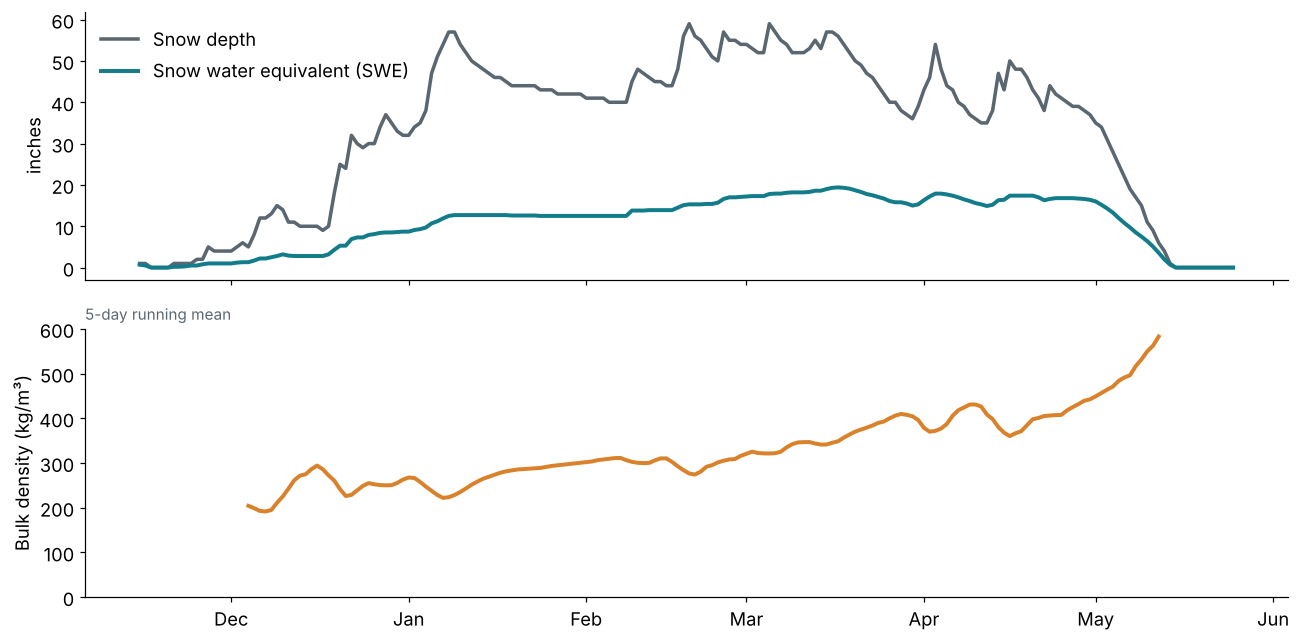

In [10]:
b26 = get_snotel(312, "ID", "2025-10-01", "2026-09-30", "WTEQ::value,SNWD::value")
b26.columns = ["swe", "depth"]
w = b26["2025-11-15":"2026-05-25"].copy()
# Density is noisy when the snow is very shallow, so only compute it when depth >= 6 inches
w["density"] = (1000 * w.swe / w.depth).where(w.depth >= 6)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a1.plot(w.index, w.depth, color=BASALT, lw=2.3, label="Snow depth")
a1.plot(w.index, w.swe, color=RIVER, lw=2.6, label="Snow water equivalent (SWE)")
a1.set_ylabel("inches"); a1.legend(frameon=False, loc="upper left")
a2.plot(w.index, w.density.rolling(5, center=True, min_periods=3).mean(), color=OCHRE, lw=2.6)
a2.set_ylabel("Bulk density (kg/m³)"); a2.set_ylim(0, 600)
a2.set_title("5-day running mean", loc="left", fontsize=10, color=BASALT)
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b")); a2.xaxis.set_major_locator(mdates.MonthLocator())
plt.tight_layout()

for day in ["2026-01-09", "2026-02-08"]:
    r = w.loc[day]
    print(f"{day}: depth {r.depth:.0f} in, SWE {r.swe:.1f} in, density {1000 * r.swe / r.depth:.0f} kg/m³")

Between January 9 and February 8, 2026, the snow got about 17 inches shallower, but its SWE barely changed. If you'd measured only depth, you'd think almost a third of the snowpack had melted. It hadn't; it just settled.

## 7. Your turn

1. **How did the 2026 forecast do?** Change the end date in the `get_usgs_daily_flow` call to `"2026-09-30"`, re-run, and compute the observed April-July 2026 volume at Lowman. Was it inside the 95% range? Above or below the forecast? Using what you learned in Module 04, explain why. (WY2026 data are provisional.)
2. **Leave-one-out test.** A fair test of a forecast uses only data the forecaster had. Remove one year (say 2017) from `years`, refit, and forecast that year. How far off is it? Try a few years. Which kinds of years does the line handle worst?
3. **Add precipitation.** NRCS forecasters use more than SWE. Add April 1 accumulated precipitation (`banner.precip`) as a second predictor with `np.linalg.lstsq`. Does $R^2$ improve?
4. **Climate change and the line.** Split the record into 1981-2003 and 2004-2025 and fit each half separately. Has the relationship changed? What would that mean for forecasts built on old data?

### Why code?
NRCS issues water supply forecasts like this for hundreds of western rivers every month from January to June, using statistical models that are more sophisticated versions of this one. With code, refitting the model with a new year of data, testing it fairly, or swapping in a different station takes seconds.

---
*Data: USDA NRCS SNOTEL (Report Generator) and USGS NWIS. WY2026 data are provisional.*